In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Câu 1

In [3]:
# Câu 1
# Trong số các khách hàng có nhiều hơn một đơn hàng, trung vị số ngày giữa hai lần
# mua liên tiếp (inter-order gap) xấp xỉ là bao nhiêu? (Tính từ orders.csv)
dfOrder =  pd.read_csv("Transaction/orders.csv")
dfOrder["order_date"] = pd.to_datetime(dfOrder["order_date"])
dfOrder.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 646945 entries, 0 to 646944
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   order_id        646945 non-null  int64         
 1   order_date      646945 non-null  datetime64[ns]
 2   customer_id     646945 non-null  int64         
 3   zip             646945 non-null  int64         
 4   order_status    646945 non-null  object        
 5   payment_method  646945 non-null  object        
 6   device_type     646945 non-null  object        
 7   order_source    646945 non-null  object        
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 39.5+ MB


In [4]:
import pandas as pd

dfOrder['gap'] = dfOrder.groupby('customer_id')['order_date'].diff().dt.days

# lọc khách có >1 đơn (gap != null)
gaps = dfOrder['gap'].dropna()

# median
median_gap = gaps.median()

print(median_gap)

144.0


In [5]:
dfProduct = pd.read_csv("Master/products.csv")
dfProduct.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2412 entries, 0 to 2411
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    2412 non-null   int64  
 1   product_name  2412 non-null   object 
 2   category      2412 non-null   object 
 3   segment       2412 non-null   object 
 4   size          2412 non-null   object 
 5   color         2412 non-null   object 
 6   price         2412 non-null   float64
 7   cogs          2412 non-null   float64
dtypes: float64(2), int64(1), object(5)
memory usage: 150.9+ KB


In [6]:
dfProduct.describe()

,product_id,price,cogs
count,2412.000000,2412.000000,2412.000000
mean,1206.500000,4928.216231,3868.346732
std,696.428747,4776.737669,3878.584151
min,1.000000,9.056594,5.183829
25%,603.750000,59.444924,35.066367
50%,1206.500000,4399.605000,3184.934093
75%,1809.250000,7720.513784,5864.916462
max,2412.000000,40950.000000,38902.500000


In [7]:
dfProduct.head()

,product_id,product_name,category,segment,size,color,price,cogs
0,536,SaigonFlex UC-01,Streetwear,Everyday,S,green,11059.650000,9704.842875
1,537,SaigonFlex UC-02,Streetwear,Everyday,M,silver,9523.076013,5393.870254
2,538,SaigonFlex UC-03,Streetwear,Everyday,L,pink,15951.633158,11371.919278
3,539,SaigonFlex UC-04,Streetwear,Everyday,XL,yellow,15753.717299,8573.172954
4,540,SaigonFlex UC-05,Streetwear,Everyday,S,red,15766.334536,14063.570406


## Câu 2

In [9]:
# Phân khúc sản phẩm (segment) nào trong products.csv có tỷ suất lợi nhuận gộp
# trung bình cao nhất, với công thức (price − cogs)/price? - lấy từ products.csv 

dfProduct["cost"] = (dfProduct["price"] - dfProduct["cogs"])/dfProduct["price"]

In [10]:
dfProduct.groupby("segment")["cost"].mean().sort_values()

segment
Everyday       0.236343
Trendy         0.240758
Balanced       0.258038
Performance    0.263650
Activewear     0.265600
All-weather    0.284176
Premium        0.285377
Standard       0.313442
Name: cost, dtype: float64

## Câu 3

In [12]:
# Trong các bản ghi trả hàng liên kết với sản phẩm thuộc danh mục Streetwear (join
# returns với products theo product_id), lý do trả hàng nào xuất hiện nhiều nhất?
dfReturn = pd.read_csv("Transaction/returns.csv")
dfReturn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39939 entries, 0 to 39938
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   return_id        39939 non-null  object 
 1   order_id         39939 non-null  int64  
 2   product_id       39939 non-null  int64  
 3   return_date      39939 non-null  object 
 4   return_reason    39939 non-null  object 
 5   return_quantity  39939 non-null  int64  
 6   refund_amount    39939 non-null  float64
dtypes: float64(1), int64(3), object(3)
memory usage: 2.1+ MB


In [13]:
dfReturn.head()

,return_id,order_id,product_id,return_date,return_reason,return_quantity,refund_amount
0,RET-000001,2,609,2012-07-25,late_delivery,6,52458.01
1,RET-000002,32,1862,2012-07-16,wrong_size,2,5141.37
2,RET-000003,35,2359,2012-07-16,wrong_size,1,5315.95
3,RET-000004,47,1449,2012-07-11,wrong_size,4,6493.75
4,RET-000005,47,1450,2012-07-25,wrong_size,1,1740.76


In [14]:
dfReturn.duplicated().sum()

0

In [15]:
dfProducts_Streetwear = dfProduct[dfProduct["category"] == "Streetwear"]
dfProducts_Streetwear.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1320 entries, 0 to 1319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    1320 non-null   int64  
 1   product_name  1320 non-null   object 
 2   category      1320 non-null   object 
 3   segment       1320 non-null   object 
 4   size          1320 non-null   object 
 5   color         1320 non-null   object 
 6   price         1320 non-null   float64
 7   cogs          1320 non-null   float64
 8   cost          1320 non-null   float64
dtypes: float64(3), int64(1), object(5)
memory usage: 103.1+ KB


In [16]:
returnStreetwear = dfReturn.merge(dfProducts_Streetwear, on='product_id', how='inner')

In [17]:
returnStreetwear["return_reason"].value_counts()

return_reason
wrong_size          7626
defective           4330
not_as_described    3854
changed_mind        3830
late_delivery       2159
Name: count, dtype: int64

## Câu 4

In [19]:
dfWebtraffic = pd.read_csv("Operational/web_traffic.csv")
dfWebtraffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3652 entries, 0 to 3651
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date                      3652 non-null   object 
 1   sessions                  3652 non-null   int64  
 2   unique_visitors           3652 non-null   int64  
 3   page_views                3652 non-null   int64  
 4   bounce_rate               3652 non-null   float64
 5   avg_session_duration_sec  3652 non-null   float64
 6   traffic_source            3652 non-null   object 
dtypes: float64(2), int64(3), object(2)
memory usage: 199.8+ KB


In [20]:
dfWebtraffic

,date,sessions,unique_visitors,page_views,bounce_rate,avg_session_duration_sec,traffic_source
0,2013-01-01,9760,7253,39093,0.00514,102.9,organic_search
1,2013-01-02,10456,8151,47611,0.00406,120.5,organic_search
2,2013-01-03,10076,7458,36963,0.00401,263.6,direct
3,2013-01-04,9973,8063,53078,0.00562,151.8,direct
4,2013-01-05,10223,7882,36790,0.00525,168.6,referral
...,...,...,...,...,...,...,...
3647,2022-12-27,17416,13150,62527,0.00506,252.4,organic_search
3648,2022-12-28,21071,15979,67456,0.00560,177.3,organic_search
3649,2022-12-29,20884,14640,82155,0.00522,165.6,direct
3650,2022-12-30,17679,13713,79308,0.00350,183.8,email_campaign


In [21]:
dfWebtraffic.groupby(["traffic_source"])["bounce_rate"].mean().reset_index().sort_values(by = "bounce_rate" )

,traffic_source,bounce_rate
1,email_campaign,0.004458
5,social_media,0.004476
3,paid_search,0.004478
4,referral,0.004499
2,organic_search,0.004504
0,direct,0.004511


## Câu 5

In [23]:
# Tỷ lệ phần trăm các dòng trong order_items.csv có áp dụng khuyến mãi (tức là promo_id không null) xấp xỉ là bao nhiêu?
dfOrder_Item = pd.read_csv("Transaction/order_items.csv")
dfOrder_Item.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714669 entries, 0 to 714668
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         714669 non-null  int64  
 1   product_id       714669 non-null  int64  
 2   quantity         714669 non-null  int64  
 3   unit_price       714669 non-null  float64
 4   discount_amount  714669 non-null  float64
 5   promo_id         276316 non-null  object 
 6   promo_id_2       206 non-null     object 
dtypes: float64(2), int64(3), object(2)
memory usage: 38.2+ MB


C:\Users\DANG DUY\AppData\Local\Temp\ipykernel_10524\1953330195.py:2: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  dfOrder_Item = pd.read_csv("Transaction/order_items.csv")


In [24]:
dfOrder_Item["promo_id"].value_counts()

promo_id
PROMO-0014    11451
PROMO-0010    11345
PROMO-0004    11126
PROMO-0020    10121
PROMO-0011     9594
PROMO-0007     9373
PROMO-0021     8966
PROMO-0017     8808
PROMO-0001     8523
PROMO-0024     8205
PROMO-0028     8146
PROMO-0002     7754
PROMO-0027     7518
PROMO-0022     7506
PROMO-0013     7498
PROMO-0008     7089
PROMO-0018     7089
PROMO-0012     6802
PROMO-0003     6277
PROMO-0019     5763
PROMO-0009     5637
PROMO-0023     5413
PROMO-0025     5385
PROMO-0015     5072
PROMO-0030     5026
PROMO-0005     4887
PROMO-0047     4791
PROMO-0031     4718
PROMO-0037     4661
PROMO-0041     4639
PROMO-0029     4328
PROMO-0034     4277
PROMO-0032     3867
PROMO-0050     3500
PROMO-0044     3462
PROMO-0040     3286
PROMO-0035     3174
PROMO-0033     3101
PROMO-0048     3091
PROMO-0038     3074
PROMO-0042     2999
PROMO-0006     2828
PROMO-0039     2593
PROMO-0049     2568
PROMO-0016     2526
PROMO-0043     2476
PROMO-0045     2432
PROMO-0026     1881
PROMO-0036     1082
PROMO-0046 

In [25]:
276316 /714669 

0.3866349316956521

In [26]:
## Câu 6

In [27]:
# Trong customers.csv, xét các khách hàng có age_group khác null, nhóm tuổi nào có số
# đơn hàng trung bình trên mỗi khách hàng cao nhất? (tổng số đơn / số khách hàng trong
# nhóm)

dfCustomer = pd.read_csv("Master/customers.csv")
dfCustomer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121930 entries, 0 to 121929
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   customer_id          121930 non-null  int64 
 1   zip                  121930 non-null  int64 
 2   city                 121930 non-null  object
 3   signup_date          121930 non-null  object
 4   gender               121930 non-null  object
 5   age_group            121930 non-null  object
 6   acquisition_channel  121930 non-null  object
dtypes: int64(2), object(5)
memory usage: 6.5+ MB


In [28]:
totalCus = dfCustomer["age_group"].value_counts().reset_index()
totalCus

,age_group,count
0,25-34,36342
1,35-44,31920
2,45-54,23172
3,18-24,17039
4,55+,13457


In [29]:
oderAgeGroup = dfCustomer.merge(dfOrder, on='customer_id', how='inner')

In [30]:
oderAgeGroup.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 646945 entries, 0 to 646944
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   customer_id          646945 non-null  int64         
 1   zip_x                646945 non-null  int64         
 2   city                 646945 non-null  object        
 3   signup_date          646945 non-null  object        
 4   gender               646945 non-null  object        
 5   age_group            646945 non-null  object        
 6   acquisition_channel  646945 non-null  object        
 7   order_id             646945 non-null  int64         
 8   order_date           646945 non-null  datetime64[ns]
 9   zip_y                646945 non-null  int64         
 10  order_status         646945 non-null  object        
 11  payment_method       646945 non-null  object        
 12  device_type          646945 non-null  object        
 13  order_source  

In [31]:
ageGrouphaveOrder = oderAgeGroup["age_group"].value_counts().reset_index()
ageGrouphaveOrder

,age_group,count
0,25-34,190622
1,35-44,170368
2,45-54,124138
3,18-24,89057
4,55+,72760


In [32]:
orderPerCus =  ageGrouphaveOrder.merge(totalCus, on='age_group', how='inner')
orderPerCus["per"] = orderPerCus["count_x"] / orderPerCus["count_y"]
orderPerCus

,age_group,count_x,count_y,per
0,25-34,190622,36342,5.245226
1,35-44,170368,31920,5.337343
2,45-54,124138,23172,5.357241
3,18-24,89057,17039,5.226656
4,55+,72760,13457,5.406851


## Câu 7

In [64]:
# Vùng (region) nào trong geography.csv tạo ra tổng doanh thu cao nhất trong
# sales_train.csv?
# A) West
# B) Central
# C) East
# D) Cả ba vùng có doanh thu xấp xỉ bằng nhau
dfGeo =  pd.read_csv("Master/geography.csv")
dfGeo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39948 entries, 0 to 39947
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   zip       39948 non-null  int64 
 1   city      39948 non-null  object
 2   region    39948 non-null  object
 3   district  39948 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.2+ MB


In [68]:
dfPayment = pd.read_csv("Transaction/payments.csv")
dfPayment.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 646945 entries, 0 to 646944
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   order_id        646945 non-null  int64  
 1   payment_method  646945 non-null  object 
 2   payment_value   646945 non-null  float64
 3   installments    646945 non-null  int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 19.7+ MB


In [78]:
dfOrder =  pd.read_csv("Transaction/orders.csv")
dfOrder.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 646945 entries, 0 to 646944
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   order_id        646945 non-null  int64 
 1   order_date      646945 non-null  object
 2   customer_id     646945 non-null  int64 
 3   zip             646945 non-null  int64 
 4   order_status    646945 non-null  object
 5   payment_method  646945 non-null  object
 6   device_type     646945 non-null  object
 7   order_source    646945 non-null  object
dtypes: int64(3), object(5)
memory usage: 39.5+ MB


In [80]:
dfOrder

,order_id,order_date,customer_id,zip,order_status,payment_method,device_type,order_source
0,1,2012-07-04,58578,1109,delivered,credit_card,desktop,paid_search
1,2,2012-07-04,58621,1330,returned,cod,mobile,paid_search
2,3,2012-07-04,58811,1473,delivered,credit_card,desktop,direct
3,4,2012-07-04,59453,2360,delivered,credit_card,desktop,referral
4,6,2012-07-06,57821,2886,delivered,paypal,mobile,email_campaign
...,...,...,...,...,...,...,...,...
646940,834372,2022-12-31,19490,33907,delivered,credit_card,mobile,email_campaign
646941,834377,2022-12-31,73046,37091,delivered,credit_card,mobile,referral
646942,834387,2022-12-31,107723,80516,delivered,credit_card,mobile,email_campaign
646943,834392,2022-12-31,139431,93510,delivered,paypal,desktop,direct


In [100]:
salebyOrderTrain = dfOrder[(dfOrder["order_date"] >= "04-07-2012") & (dfOrder["order_date"] <= "31-12-2022")]
salebyOrderTrain.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 646945 entries, 0 to 646944
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   order_id        646945 non-null  int64 
 1   order_date      646945 non-null  object
 2   customer_id     646945 non-null  int64 
 3   zip             646945 non-null  int64 
 4   order_status    646945 non-null  object
 5   payment_method  646945 non-null  object
 6   device_type     646945 non-null  object
 7   order_source    646945 non-null  object
dtypes: int64(3), object(5)
memory usage: 39.5+ MB


In [96]:
RevenuebyGeo = salebyOrderTrain.merge(dfPayment, on='order_id', how='inner')
RevenuebyGeo = RevenuebyGeo.merge(dfGeo, on='zip', how='inner')

In [98]:
RevenuebyGeo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 646945 entries, 0 to 646944
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   order_id          646945 non-null  int64  
 1   order_date        646945 non-null  object 
 2   customer_id       646945 non-null  int64  
 3   zip               646945 non-null  int64  
 4   order_status      646945 non-null  object 
 5   payment_method_x  646945 non-null  object 
 6   device_type       646945 non-null  object 
 7   order_source      646945 non-null  object 
 8   payment_method_y  646945 non-null  object 
 9   payment_value     646945 non-null  float64
 10  installments      646945 non-null  int64  
 11  city              646945 non-null  object 
 12  region            646945 non-null  object 
 13  district          646945 non-null  object 
dtypes: float64(1), int64(4), object(9)
memory usage: 69.1+ MB


In [ ]:
# payment_value - Tổng giá trị thanh toán của đơn hàng

In [102]:
RevenuebyGeo.groupby("region")["payment_value"].sum()

region
Central    4.719491e+09
East       7.291151e+09
West       3.670227e+09
Name: payment_value, dtype: float64

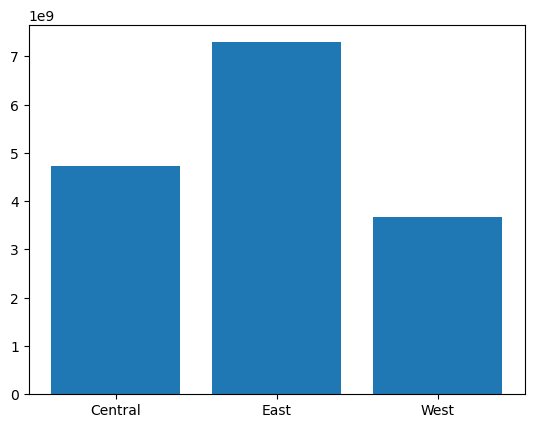

In [106]:
plt.bar(
    RevenuebyGeo.groupby("region")["payment_value"].sum().index,
    RevenuebyGeo.groupby("region")["payment_value"].sum().values,
)
plt.show()

## Câu 8

In [115]:
# Trong các đơn hàng có order_status = ’cancelled’ trong orders.csv, phương thức
# thanh toán nào được sử dụng nhiều nhất?
dfOrder =  pd.read_csv("Transaction/orders.csv")
dfOrder_status_cancelled = dfOrder[dfOrder["order_status"] == "cancelled"]
dfOrder["order_status"].value_counts()

order_status
delivered    516716
cancelled     59462
returned      36142
shipped       13773
paid          13577
created        7275
Name: count, dtype: int64

In [117]:
dfOrder_status_cancelled.info()

<class 'pandas.core.frame.DataFrame'>
Index: 59462 entries, 16 to 646926
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   order_id        59462 non-null  int64 
 1   order_date      59462 non-null  object
 2   customer_id     59462 non-null  int64 
 3   zip             59462 non-null  int64 
 4   order_status    59462 non-null  object
 5   payment_method  59462 non-null  object
 6   device_type     59462 non-null  object
 7   order_source    59462 non-null  object
dtypes: int64(3), object(5)
memory usage: 4.1+ MB


In [121]:
dfOrder_status_cancelled["payment_method"].value_counts(normalize=True)*100

payment_method
credit_card      47.849046
cod              26.013252
paypal           13.146211
apple_pay         8.728263
bank_transfer     4.263227
Name: proportion, dtype: float64

## Câu 9

In [124]:
# Trong bốn kích thước sản phẩm (S, M, L, XL), kích thước nào có tỷ lệ trả hàng cao
# nhất, được định nghĩa là số bản ghi trong returns chia cho số dòng trong order_items (join
# với products theo product_id)?
# A) S
# B) M
# C) L
# D) XL
dfProduct = pd.read_csv("Master/products.csv")
dfProduct.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2412 entries, 0 to 2411
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    2412 non-null   int64  
 1   product_name  2412 non-null   object 
 2   category      2412 non-null   object 
 3   segment       2412 non-null   object 
 4   size          2412 non-null   object 
 5   color         2412 non-null   object 
 6   price         2412 non-null   float64
 7   cogs          2412 non-null   float64
dtypes: float64(2), int64(1), object(5)
memory usage: 150.9+ KB


In [130]:
dfOrder_Item = pd.read_csv("Transaction/order_items.csv")
dfOrder_Item.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714669 entries, 0 to 714668
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         714669 non-null  int64  
 1   product_id       714669 non-null  int64  
 2   quantity         714669 non-null  int64  
 3   unit_price       714669 non-null  float64
 4   discount_amount  714669 non-null  float64
 5   promo_id         276316 non-null  object 
 6   promo_id_2       206 non-null     object 
dtypes: float64(2), int64(3), object(2)
memory usage: 38.2+ MB


C:\Users\DANG DUY\AppData\Local\Temp\ipykernel_10524\174196762.py:1: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  dfOrder_Item = pd.read_csv("Transaction/order_items.csv")


In [132]:
dfReturn = pd.read_csv("Transaction/returns.csv")
dfReturn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39939 entries, 0 to 39938
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   return_id        39939 non-null  object 
 1   order_id         39939 non-null  int64  
 2   product_id       39939 non-null  int64  
 3   return_date      39939 non-null  object 
 4   return_reason    39939 non-null  object 
 5   return_quantity  39939 non-null  int64  
 6   refund_amount    39939 non-null  float64
dtypes: float64(1), int64(3), object(3)
memory usage: 2.1+ MB
